# 06 · Try the fine-tuned SmolVLM-500M on a few images
**Run all** (Runtime → Run all). About 3 minutes on a T4: no dataset download, the 8 demo images ship with the repo in `examples/` (val split: never trained on, never the locked test).
Green box = true defect region, red box = the model's predicted region. Section 3 lets you upload your own photo.
Needs the adapter trained in notebook 03 at `MyDrive/InspectEdge/checkpoints/<RUN>/final`.

**Also runs locally in VS Code** (Jupyter extension, kernel = the repo's `.venv`): download the Drive folder `InspectEdge/checkpoints/<RUN>/final` into `checkpoints/<RUN>/final` in the repo, then Run All. Uses the local GPU if there is one (fp16), else CPU (slow, ~1 min per image).

In [1]:
import os, sys
try:
    import google.colab; COLAB = True
except ImportError:
    COLAB = False
if COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE, WORK = '/content/drive/MyDrive/InspectEdge', '/content/InspectEdge'
    if os.path.isdir(f'{WORK}/.git'):
        !git -C {WORK} pull -q --ff-only
    else:
        !git clone -q https://github.com/moghbaie/InspectEdge_Mobile_VLM.git {WORK}
    %cd {WORK}
    !pip -q install -r requirements-colab.txt && pip -q install -e . --no-deps
    CKPT = f'{DRIVE}/checkpoints'
else:   # local (VS Code / Jupyter): the notebook sits in <repo>/notebooks
    WORK = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
    os.chdir(WORK)
    CKPT = f'{WORK}/checkpoints'
os.environ['INSPECTEDGE_ROOT'] = WORK
sys.path.insert(0, f'{WORK}/src')   # an editable install's .pth is only read at kernel start; in-kernel imports need this
import torch, transformers
assert transformers.__version__ == '4.57.1', 'pinned transformers not active: restart the kernel/session, then Run all again'
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('running on', torch.cuda.get_device_name(0) if DEV == 'cuda' else 'CPU (slow: about a minute per image)')

Mounted at /content/drive
/content/InspectEdge
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for inspectedge (pyproject.toml) ... done


## 1. Load the model

In [2]:
RUN = 'smolvlm500m_lora_r16_lr2e-4_s0'   # val winner (notebook 05, section 5); change to try another run
BASE = 'HuggingFaceTB/SmolVLM-500M-Instruct'

import io, json, time, matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from peft import PeftModel
from inspectedge.vlm.prompting import build_messages
from inspectedge.schemas.report import parse_model_output

ADAPTER, LONGEST_EDGE = f'{CKPT}/{RUN}/final', 1024   # same image size as eval_vlm.py
assert os.path.isdir(ADAPTER), (f'no adapter at {ADAPTER}: ' + ('train it in notebook 03 first' if COLAB else
    f'download the Drive folder InspectEdge/checkpoints/{RUN}/final to this path'))
dtype = (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16) if DEV == 'cuda' else torch.float32
proc = AutoProcessor.from_pretrained(ADAPTER)
if 'longest_edge' in getattr(proc.image_processor, 'size', {}):
    proc.image_processor.size = {'longest_edge': LONGEST_EDGE}
model = AutoModelForImageTextToText.from_pretrained(BASE, dtype=dtype).to(DEV)
model = PeftModel.from_pretrained(model, ADAPTER).merge_and_unload().eval()   # merged: faster generation

def inspect(img, category):
    """Image + category -> (ParseResult, raw text, seconds). Same prompt and greedy decoding as eval_vlm.py."""
    prompt = proc.apply_chat_template(build_messages(category), add_generation_prompt=True)
    inputs = proc(text=[prompt], images=[[img]], return_tensors='pt').to(model.device)
    inputs['pixel_values'] = inputs['pixel_values'].to(dtype)
    if DEV == 'cuda': torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=320, do_sample=False)
    if DEV == 'cuda': torch.cuda.synchronize()
    text = proc.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)[0]
    return parse_model_output(text), text, time.perf_counter() - t0

def draw(ax, boxes, size, color):
    W, H = size
    for b in boxes or []:
        if isinstance(b, (list, tuple)) and len(b) == 4 and all(isinstance(v, (int, float)) for v in b):
            ax.add_patch(patches.Rectangle((b[0] * W, b[1] * H), (b[2] - b[0]) * W, (b[3] - b[1]) * H, fill=False, ec=color, lw=2))

def show(img, category, truth=None):
    """Run the model and plot. truth = an examples.json entry (adds ground truth), or None for your own photo."""
    pr, text, dt = inspect(img, category)
    rep = pr.parsed if pr.json_ok and isinstance(pr.parsed, dict) else {}
    finds = [f for f in rep['findings'] if isinstance(f, dict)] if isinstance(rep.get('findings'), list) else []
    status = rep.get('inspection_status', 'INVALID OUTPUT')
    fig, ax = plt.subplots(figsize=(5, 5)); ax.imshow(img); ax.axis('off')
    title, ok = f'{category} | model: {status}', None
    if truth:
        ok = (status == 'visible_anomaly') == (truth['label'] == 'anomaly') and pr.schema_ok
        title += f"\ntruth: {truth['label']} {truth['defect_types'] or ''} -> {'CORRECT' if ok else 'WRONG'}"
        draw(ax, truth['boxes'], img.size, 'lime')
    draw(ax, [f.get('region_xyxy_normalized') for f in finds], img.size, 'red')
    ax.set_title(title, fontsize=10); plt.show()
    print(f'{dt:.1f}s | valid report: {pr.schema_ok}' + (f' | problems: {pr.errors[:2]}' if pr.errors else ''))
    for f in finds:
        print(f"  - {f.get('type')}: {f.get('visible_evidence')} (review_required={f.get('review_required')})")
    q = rep.get('image_quality') if isinstance(rep.get('image_quality'), dict) else {}
    if q: print('  image quality:', 'usable' if q.get('usable') else 'NOT usable', q.get('issues') or '')
    if not pr.json_ok: print('raw output:', text[:500])
    return ok
print('ready:', RUN)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.02G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

ready: smolvlm500m_lora_r16_lr2e-4_s0


## 2. The 8 demo images (val split)

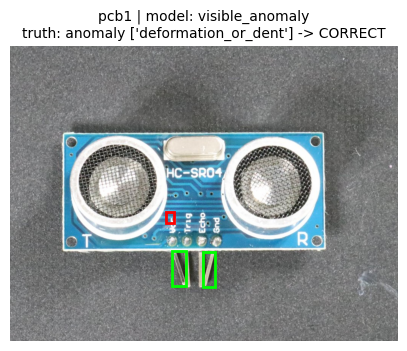

20.7s | valid report: True
  - deformation_or_dent: melt (review_required=True)
  image quality: usable 


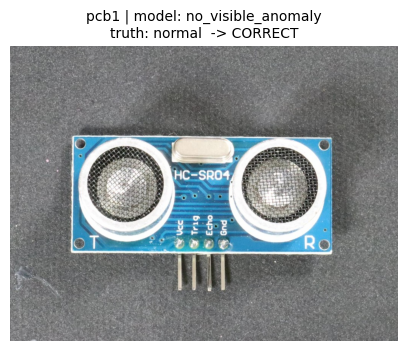

6.2s | valid report: True
  image quality: usable 


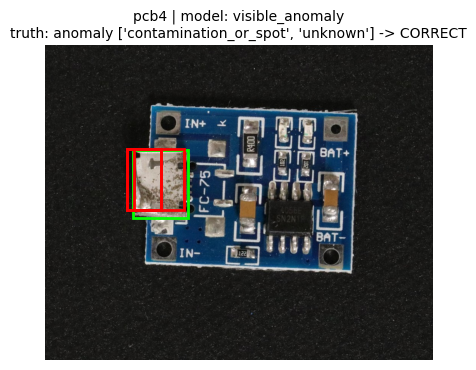

19.3s | valid report: True
  - missing_or_misplaced_component: missing (review_required=True)
  - missing_or_misplaced_component: missing (review_required=True)
  - missing_or_misplaced_component: missing (review_required=True)
  image quality: usable 


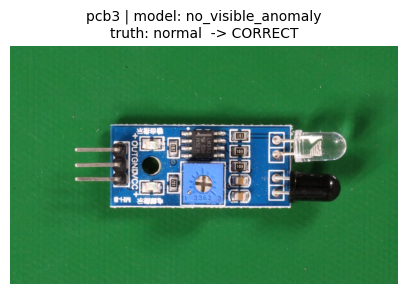

3.4s | valid report: True
  image quality: usable 


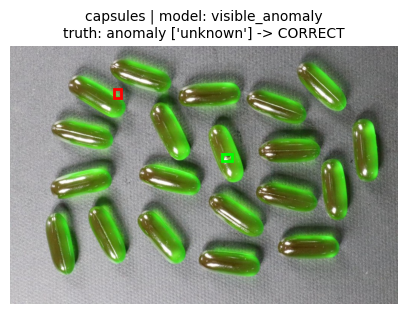

5.9s | valid report: True
  - discoloration: bubble, discolor, scratch, leak, misshape (review_required=True)
  image quality: usable 


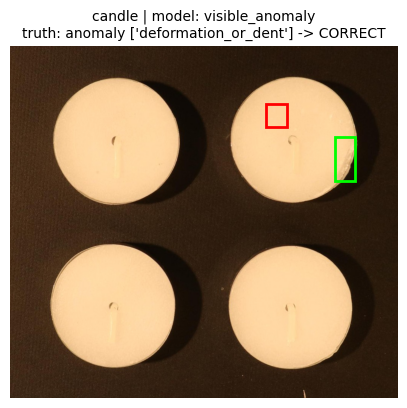

6.7s | valid report: True
  - deformation_or_dent: damaged corner of packaging (review_required=True)
  image quality: usable 


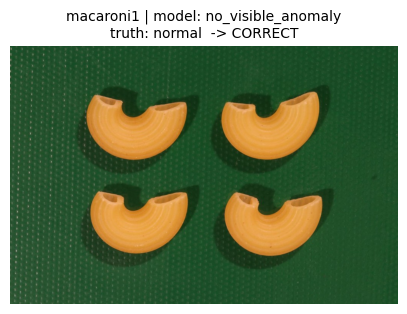

3.2s | valid report: True
  image quality: usable 


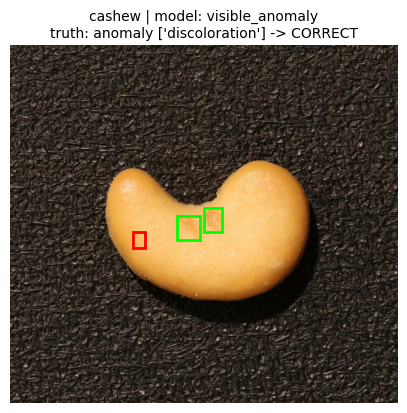

5.4s | valid report: True
  - discoloration: burnt (review_required=True)
  image quality: usable 

8/8 correct on the demo images (full-val accuracy is in notebook 05, section 5)


In [3]:
EXAMPLES = json.load(open('examples/examples.json'))
results = [show(Image.open(f"examples/{e['file']}").convert('RGB'), e['category'], e) for e in EXAMPLES]
print(f'\n{sum(results)}/{len(results)} correct on the demo images (full-val accuracy is in notebook 05, section 5)')

Optional: the same defective PCB as a dark and a blurry photo. The model was trained with these corruptions and should report the quality problem rather than guess.

===== low_light =====


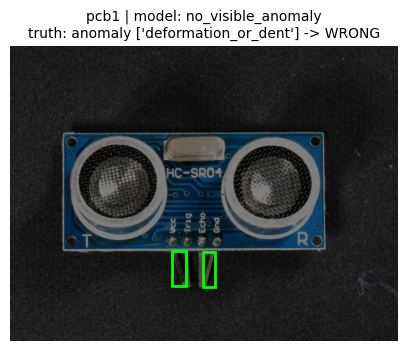

3.9s | valid report: True
  image quality: usable ['low_light']
===== motion_blur =====


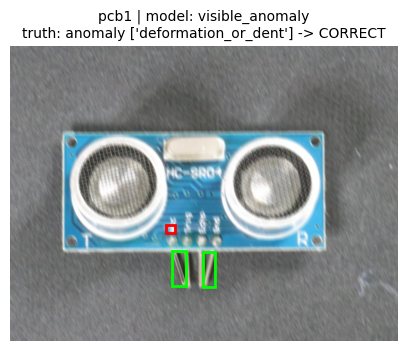

6.6s | valid report: True
  - deformation_or_dent: melt (review_required=True)
  image quality: usable ['blur']


In [4]:
import numpy as np
from inspectedge.augmentation.corruptions import apply as corrupt
e = next(x for x in EXAMPLES if x['file'] == 'pcb1_anomaly.jpg')
arr = np.asarray(Image.open(f"examples/{e['file']}").convert('RGB'))
for fam in ['low_light', 'motion_blur']:
    print(f'===== {fam} =====')
    show(Image.fromarray(corrupt(arr, fam, 3, seed=0)[0]), e['category'], e)

## 3. Your own photo
Set `CATEGORY` to the closest of: candle, capsules, cashew, chewinggum, fryum, macaroni1, macaroni2, pcb1, pcb2, pcb3, pcb4, pipe_fryum. The model only knows these 12 VisA objects photographed on a rig, so phone photos of other things are out of its training range.
In Colab an upload button appears; locally, list the file paths in `MY_PHOTOS`.

In [ ]:
CATEGORY = 'pcb1'
MY_PHOTOS = []   # local only, e.g. [r'C:\Users\me\Pictures\board.jpg']
if COLAB:
    from google.colab import files
    photos = [io.BytesIO(data) for data in files.upload().values()]
else:
    photos = MY_PHOTOS
for src in photos:
    img = Image.open(src).convert('RGB'); img.thumbnail((LONGEST_EDGE, LONGEST_EDGE))
    show(img, CATEGORY)